In [2]:
import anndata as ad, numpy as np, pandas as pd

MCK = "/n/lab_storage/eddy_lab/Lab/mckinley_backup_2025-12-18/data"
OUT_DIR = "/n/lab_storage/eddy_lab/users/nhilgert/xmens_final/data/interim"  # ← writes here, NOT back to McKinley
import os; os.makedirs(OUT_DIR, exist_ok=True)

PAIRS = [
    ("20251008_Cevrim_Human_All_Cells.h5ad",          "2026_08_05_Cevrim_Human_All_Cells.h5ad"),
    ("20251008_Cevrim_Human_Only_Fib_Dec_Cells.h5ad", "2026_08_05_Cevrim_Human_Only_Fib_Dec_Cells.h5ad"),
    ("20251008_Cevrim_XMens_All_Cells.h5ad",           "2026_08_05_Cevrim_XMens_All_Cells.h5ad"),
    ("20251008_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad",  "2026_08_05_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad"),
]
COORD_COLS = ["x_um_dbscan", "y_um_dbscan"]

# canonical key (same logic as prior joins) — used as fallback if obs_names don't match
def canon(s):
    s = s.astype(str).str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
    return s.str.replace("bleeding", "menstrual", regex=False)
def build_key(obs):
    bc = obs["cell_barcode"] if "cell_barcode" in obs else pd.Series(obs.index, index=obs.index)
    bc = bc.astype(str).str.replace(r"-\d+$", "", regex=True)
    if "sample" in obs: return (canon(obs["sample"]) + "||" + bc).values
    return bc.values

for old_name, new_name in PAIRS:
    print("="*70, f"\n{new_name}")
    old = ad.read_h5ad(f"{MCK}/{old_name}", backed="r")
    new = ad.read_h5ad(f"{MCK}/{new_name}")   # read fully (we'll modify + write)

    # confirm old has the coords
    missing_coords = [c for c in COORD_COLS if c not in old.obs.columns]
    if missing_coords:
        print(f"  SKIP: old object missing {missing_coords}. old obs coord-ish: "
              f"{[c for c in old.obs.columns if 'um' in c.lower()]}"); continue

    old_obs = old.obs[COORD_COLS].copy()

    # --- try direct obs_names join first ---
    direct = new.obs_names.isin(old.obs_names)
    print(f"  direct obs_names overlap: {int(direct.sum())}/{new.n_obs} ({100*direct.mean():.1f}%)")

    if direct.mean() > 0.95:
        # direct barcode match works
        aligned = old_obs.reindex(new.obs_names)
        key_used = "obs_names"
    else:
        # fall back to canonical sample||barcode key
        old_key = build_key(old.obs); new_key = build_key(new.obs)
        old_by_key = pd.DataFrame(old_obs.values, index=old_key, columns=COORD_COLS)
        old_by_key = old_by_key[~old_by_key.index.duplicated(keep="first")]
        aligned = old_by_key.reindex(new_key)
        aligned.index = new.obs_names
        matched = aligned[COORD_COLS[0]].notna().sum()
        print(f"  canonical-key overlap: {int(matched)}/{new.n_obs} ({100*matched/new.n_obs:.1f}%)")
        key_used = "sample||barcode"

    # report unmatched
    n_missing = aligned[COORD_COLS[0]].isna().sum()
    if n_missing:
        print(f"  WARNING: {n_missing} cells got NO coordinates (no match in old object) -> NaN")

    # write coords onto new object
    for c in COORD_COLS:
        new.obs[c] = aligned[c].values

    out_path = f"{OUT_DIR}/{new_name}"
    new.write_h5ad(out_path)
    print(f"  key: {key_used} | wrote: {out_path}")

2026_08_05_Cevrim_Human_All_Cells.h5ad
  direct obs_names overlap: 0/66830 (0.0%)
  canonical-key overlap: 43253/66830 (64.7%)
  key: sample||barcode | wrote: /n/lab_storage/eddy_lab/users/nhilgert/xmens_final/data/interim/2026_08_05_Cevrim_Human_All_Cells.h5ad
2026_08_05_Cevrim_Human_Only_Fib_Dec_Cells.h5ad
  direct obs_names overlap: 0/47533 (0.0%)
  canonical-key overlap: 31296/47533 (65.8%)
  key: sample||barcode | wrote: /n/lab_storage/eddy_lab/users/nhilgert/xmens_final/data/interim/2026_08_05_Cevrim_Human_Only_Fib_Dec_Cells.h5ad
2026_08_05_Cevrim_XMens_All_Cells.h5ad
  direct obs_names overlap: 0/57033 (0.0%)
  canonical-key overlap: 30920/57033 (54.2%)
  key: sample||barcode | wrote: /n/lab_storage/eddy_lab/users/nhilgert/xmens_final/data/interim/2026_08_05_Cevrim_XMens_All_Cells.h5ad
2026_08_05_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad
  direct obs_names overlap: 0/43197 (0.0%)
  canonical-key overlap: 24529/43197 (56.8%)
  key: sample||barcode | wrote: /n/lab_storage/eddy_lab/user

In [1]:
import anndata as ad
import os

MCK = "/n/lab_storage/eddy_lab/Lab/mckinley_backup_2025-12-18"
OUT_DIR = "/n/lab_storage/eddy_lab/users/nhilgert/xmens_final/data/interim"  # working location
os.makedirs(OUT_DIR, exist_ok=True)

FILES = [
    "2026_08_05_Cevrim_Human_All_Cells.h5ad",
    "2026_08_05_Cevrim_Human_Only_Fib_Dec_Cells.h5ad",
    "2026_08_05_Cevrim_XMens_All_Cells.h5ad",
    "2026_08_05_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad",
]

RELABEL = {                                  # cell_subtype renames
    "decidual_border": "decidual_boundary",
    "efib_myometrial": "efib_outer",
}

# ---- safety switches ----
WRITE_BACK_TO_MCK = False   # False = write to OUT_DIR (backup left pristine). True = overwrite McKinley.
DRY_RUN           = True    # True = preview only. Set False to actually modify + write.
# -------------------------

for name in FILES:
    src = f"{MCK}/{name}"
    try:
        a = ad.read_h5ad(src)
    except FileNotFoundError:
        print(f"skip (not found): {name}"); continue
    print(f"\n{name}  ({a.n_obs} cells)")

    # --- 1. relabel cell_subtype ---
    if "cell_subtype" in a.obs.columns:
        before = set(a.obs["cell_subtype"].astype(str).unique())
        for old_lbl in RELABEL:                       # warn if an expected label isn't there
            if old_lbl not in before:
                print(f"  NOTE: '{old_lbl}' not in cell_subtype (present: {sorted(before)})")
        if not DRY_RUN:
            a.obs["cell_subtype"] = (a.obs["cell_subtype"].astype(str)
                                     .replace(RELABEL).astype("category"))
        print(f"  relabel map applied: {RELABEL}")
    else:
        print("  NOTE: no 'cell_subtype' column — skipping relabel")

    # --- 2. drop leiden columns ---
    leiden_cols = [c for c in a.obs.columns if "leiden" in c.lower()]
    print(f"  leiden columns found ({len(leiden_cols)}): {leiden_cols}")
    if leiden_cols and not DRY_RUN:
        a.obs.drop(columns=leiden_cols, inplace=True)

    # --- 3. write ---
    out = f"{MCK}/{name}" if WRITE_BACK_TO_MCK else f"{OUT_DIR}/{name}"
    if DRY_RUN:
        print(f"  DRY_RUN: would write -> {out}")
    else:
        a.write_h5ad(out)
        print(f"  wrote -> {out}")
        if "cell_subtype" in a.obs.columns:
            print(f"  final cell_subtype: {sorted(set(a.obs['cell_subtype'].astype(str)))}")

skip (not found): 2026_08_05_Cevrim_Human_All_Cells.h5ad
skip (not found): 2026_08_05_Cevrim_Human_Only_Fib_Dec_Cells.h5ad
skip (not found): 2026_08_05_Cevrim_XMens_All_Cells.h5ad
skip (not found): 2026_08_05_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad


In [2]:
import scanpy as sc

In [3]:
adata = sc.read_h5ad("/n/netscratch/eddy_lab/Everyone/nhilgert/2026_08_05_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad")

In [4]:
adata

AnnData object with n_obs × n_vars = 43197 × 33698
    obs: 'sample', 'cell_barcode', 'timepoint', 'coarse_refined', 'fine_refined', 'origin_lineage', 'leiden_scVI_0.1', 'leiden_scVI_0.2', 'leiden_scVI_0.3', 'leiden_scVI_0.4', 'leiden_scVI_0.5', 'leiden_scVI_0.6', 'leiden_scVI_0.7', 'leiden_scVI_0.8', 'leiden_scVI_0.9', 'leiden_scVI_1.0', 'leiden_scVI_1.5', 'leiden_scVI_2.0', 'leiden_scVI_2.5', 'leiden_scVI_3.0', 'leiden_scVI_4.0', 'leiden_scVI_5.0', 'leiden_scVI_6.0', 'leiden_scVI_7.0', 'leiden_scVI_8.0', 'leiden_scVI_9.0', 'leiden_scVI_10.0', 'cell_type_annotations', 'cell_type_subannotations', 'cell_subtype_annotations', 'module_MMy', 'module_MD', 'module_VSZ', 'module_FMI', 'module_C', 'module_PDZ', 'module_TDZ', 'module_SDZ', 'module_udStr', 'module_Glan', 'module_AMMy'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'hb', 'mito', 'highly_variable', 'highly_variable_rank', 'highly_variable_nbatches'
    uns: 'coarse_refined_colors', 'fine_refined_colors', 'hvg', 'lei

In [7]:
import anndata as ad, scanpy as sc, numpy as np, pandas as pd, os
from ctxcore.genesig import GeneSignature
from pyscenic.aucell import aucell, derive_auc_threshold

# ---- config ----
SCRATCH = "/n/netscratch/eddy_lab/Everyone/nhilgert"
FILES = [
    "2026_08_05_Cevrim_Human_All_Cells.h5ad",
    "2026_08_05_Cevrim_Human_Only_Fib_Dec_Cells.h5ad",
    "2026_08_05_Cevrim_XMens_All_Cells.h5ad",
    "2026_08_05_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad",
]
COUNTS_LAYER  = "counts"          # integer raw counts (AUCell input)
MODULE_PREFIX = "module_"         # new AUCell cols named module_<X> (replacing old score_genes ones)
DROP_NEIGHBOR_GRAPH = True        # also remove obsp neighbor graph + its uns metadata (leiden-adjacent)
WRITE_BACK   = True               # write to SCRATCH in place (these are your fast-disk working copies)
DRY_RUN      = True               # preview first; set False to modify+write

MODULES = {
 "MMy":  ["Actg2","Acta2","Myl9","Myh11","Tpm2","Pcp4","Col3a1","Tagln","Cnn1","Postn","Mylk","Col6a3","Acta1","Ifi27l2a","Fn1","Lum","Col1a2","Tpm1"],
 "MD":   ["Gzmf","Spp1","Gzmd","Gzme","Gzmg","Gzmc","Gzma","Prf1","Gzmb","Fcer1g","Ifitm1","AW112010","Tyrobp","Il2rb","Cd52","Tmsb15a","Chn1","Rac2","Ptn","Trbc1"],
 "VSZ":  ["Stmn2","Hmgn5","Fmo1","Wnt6","Rcn1","Hmgcs2","Tdo2","Sned1","Ntrk1","Ear2","Tac2","Susd2","Anxa5","Fbn1","Srgn","Ptn","Cxcl14","Efemp1","Tmem176a","Syt13"],
 "FMI":  ["S100a8","Srd5a1","Tfpi","Mrgprg","Bco1","2610528A11Rik","Angpt2","Tmem45a","Il1r2","Csf1r","Timp3","4930486L24Rik","Lmcd1","Masp1","Lgals3","Slc6a12","Ramp3","Ctsk","Cryaa","Txn1"],
 "C":    ["H19","Prl3d1","Ceacam15","Prl4a1","Ceacam9","Plet1","Prl7a1","Pfpl","Cts7","Mmp9","Adm","Psg29","Krt8","Plac1","Prl8a9","Efna1","Jaml","Krt18","Apoc2","Prl2a1"],
 "PDZ":  ["Prl3c1","Htra1","Fabp4","Prl8a2","Tnnc1","Gm2694","Dbi","Gm2a","Psap","Cryab","Erv3","Ctla2b","Crct1","Adamts5","Acsbg1","Krtdap","Smpd1","Gng11","Hopx"],
 "TDZ":  ["Psca","Sprr2h","Gpnmb","Erv3","Krtdap","Fabp4","Olr1","Psap","Akr1b3","Prdx6","Rgcc","Acsbg1","Hsd11b1","Dbi","Hopx","Cyb5a","Lipg","Ehd3","Dnaja4"],
 "SDZ":  ["Mt3","Mt4","Gatm","Mgp","Coch","Dio3","Sfrp5","Pdzk1ip1","Dmkn","Mt2","Atoh8","Anxa8","Mt1","Nampt","Prrx2","Tdo2","Drd4","A2m","Prkg2","Ass1"],
 "udStr":["Sfrp4","Rbp4","Igfbp5","Igfbp3","Penk","Spink8","Prxl2a","C3","Mt4","Ctla2a","Mfap4","Bgn","Itm2a","Col1a2","Igf1","Rnase4","Col1a1","Hsd11b2","Serpine2","Pcolce"],
 "Glan": ["Prss29","Spink1","Prss28","Prap1","Clu","Fxyd3","Lcn2","Wfdc2","S100g","Tmem213","Prom1","Mmp7","Aqp8","Rbp4","Cldn10","Hp","Ier3","Sfrp4","Klk1","Agr2"],
 "AMMy": ["Cnn1","Tagln","Myl9","Myh11","Prss29","Smtn","Igfbp6","Acta2","Prss28","Csrp1","Pcp4","Tpm2","Igfbp2","Apoe","Flna","Ltbp4","Actg2","Nppa","Sparcl1","Spink1"],
}

def score_aucell_cols(a, modules, counts_layer):
    m = a.copy(); m.X = m.layers[counts_layer].copy()
    chk = m.X[:50].toarray() if hasattr(m.X,"toarray") else np.asarray(m.X[:50])
    if not np.allclose(chk, np.round(chk)):
        print("    WARNING: counts layer not integer-valued — AUCell expects raw counts")
    sc.pp.normalize_total(m, target_sum=1e4)                     # CP10k, no log
    ex = pd.DataFrame(m.X.toarray() if hasattr(m.X,"toarray") else np.asarray(m.X),
                      index=m.obs_names, columns=m.var_names)
    sigs = [GeneSignature(name=n, gene2weight=[g for g in gs if g in ex.columns])
            for n, gs in modules.items()]
    thr = derive_auc_threshold(ex)[0.01]
    auc = aucell(ex, sigs, auc_threshold=thr, num_workers=8).reindex(a.obs_names)
    return auc, float(thr)

for name in FILES:
    src = f"{SCRATCH}/{name}"
    try:
        a = ad.read_h5ad(src)
    except FileNotFoundError:
        print(f"skip (not found): {name}"); continue
    print(f"\n{name}  ({a.n_obs} cells)")

    # --- leiden traces to remove (obs + uns only; neighbor graph KEPT) ---
    obs_leiden = [c for c in a.obs.columns if "leiden" in c.lower()]
    uns_leiden = [k for k in list(a.uns.keys()) if "leiden" in k.lower()]
    print(f"  obs leiden ({len(obs_leiden)}): {obs_leiden}")
    print(f"  uns leiden ({len(uns_leiden)}): {uns_leiden}")

    # --- old score_genes module cols to delete ---
    old_mods = [c for c in a.obs.columns if c.startswith("module_")]
    print(f"  old module_ cols ({len(old_mods)}): {old_mods}")

    # (neighbor graph left intact)
    print(f"  KEEPING obsp: {list(a.obsp.keys())}")

    if DRY_RUN:
        print("  DRY_RUN: no changes written.")
        continue

    # delete leiden (obs + uns) + old modules
    a.obs.drop(columns=obs_leiden + old_mods, inplace=True, errors="ignore")
    for k in uns_leiden:
        a.uns.pop(k, None)

    # recompute AUCell -> auc_<X>
    auc, thr = score_aucell_cols(a, MODULES, COUNTS_LAYER)
    print(f"  AUCell auc_threshold={thr:.4f}")
    for n in MODULES:
        if n in auc.columns:
            a.obs[f"auc_{n}"] = auc[n].values

    out = src if WRITE_BACK else f"{SCRATCH}/cleaned_{name}"
    a.write_h5ad(out)
    print(f"  wrote -> {out}")
    print(f"  new auc_ cols: {[c for c in a.obs.columns if c.startswith('auc_')]}")


2026_08_05_Cevrim_Human_All_Cells.h5ad  (66830 cells)
  obs leiden (21): ['leiden_scVI_0.1', 'leiden_scVI_0.2', 'leiden_scVI_0.3', 'leiden_scVI_0.4', 'leiden_scVI_0.5', 'leiden_scVI_0.6', 'leiden_scVI_0.7', 'leiden_scVI_0.8', 'leiden_scVI_0.9', 'leiden_scVI_1.0', 'leiden_scVI_1.5', 'leiden_scVI_2.0', 'leiden_scVI_2.5', 'leiden_scVI_3.0', 'leiden_scVI_4.0', 'leiden_scVI_5.0', 'leiden_scVI_6.0', 'leiden_scVI_7.0', 'leiden_scVI_8.0', 'leiden_scVI_9.0', 'leiden_scVI_10.0']
  uns leiden (22): ['leiden_scVI_0.1', 'leiden_scVI_0.2', 'leiden_scVI_0.3', 'leiden_scVI_0.4', 'leiden_scVI_0.5', 'leiden_scVI_0.6', 'leiden_scVI_0.7', 'leiden_scVI_0.8', 'leiden_scVI_0.9', 'leiden_scVI_1.0', 'leiden_scVI_1.5', 'leiden_scVI_10.0', 'leiden_scVI_2.0', 'leiden_scVI_2.5', 'leiden_scVI_3.0', 'leiden_scVI_3.0_colors', 'leiden_scVI_4.0', 'leiden_scVI_5.0', 'leiden_scVI_6.0', 'leiden_scVI_7.0', 'leiden_scVI_8.0', 'leiden_scVI_9.0']
  old module_ cols (0): []
  KEEPING obsp: ['neighbors_scVI_100_connectivities'

In [8]:
import anndata as ad, pandas as pd

SCRATCH = "/n/netscratch/eddy_lab/Everyone/nhilgert"
FILES = [
    "2026_08_05_Cevrim_Human_All_Cells.h5ad",
    "2026_08_05_Cevrim_Human_Only_Fib_Dec_Cells.h5ad",
    "2026_08_05_Cevrim_XMens_All_Cells.h5ad",
    "2026_08_05_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad",
]

# obs fields likely to hold cell-type / subtype annotations (from the object dump)
CANDIDATE_FIELDS = [
    "coarse_refined", "fine_refined", "origin_lineage",
    "cell_type_annotations", "cell_type_subannotations", "cell_subtype_annotations",
    "cell_type", "cell_subtype",   # in case any already use the target names
]

for name in FILES:
    print("\n" + "="*80 + f"\n{name}")
    try:
        a = ad.read_h5ad(f"{SCRATCH}/{name}", backed="r")
    except FileNotFoundError:
        print("  (not found)"); continue
    print(f"  {a.n_obs} cells")

    # which candidate fields are actually present
    present = [c for c in CANDIDATE_FIELDS if c in a.obs.columns]
    print(f"  annotation fields present: {present}")

    # also flag any OTHER obs column that looks annotation-ish (not leiden/module/QC)
    other = [c for c in a.obs.columns
             if c not in present
             and not c.startswith(("leiden","module_","auc_"))
             and any(k in c.lower() for k in ["type","subtype","annot","lineage","cluster","celltype","label"])]
    if other:
        print(f"  other annotation-ish columns: {other}")

    # for each present field: n unique + the actual values (sorted)
    for f in present:
        vals = a.obs[f].astype(str)
        uniq = sorted(vals.unique())
        print(f"\n  --- {f} ---  ({len(uniq)} unique)")
        # show value counts so you see prevalence too
        vc = vals.value_counts()
        for v in uniq:
            print(f"      {v!r}: {int(vc[v])}")


2026_08_05_Cevrim_Human_All_Cells.h5ad
  66830 cells
  annotation fields present: ['coarse_refined', 'fine_refined', 'origin_lineage', 'cell_type']
  other annotation-ish columns: ['lineage', 'subtype', 'annotation_level']

  --- coarse_refined ---  (6 unique)
      'decidual cells': 21648
      'endometrial fibroblasts': 25885
      'epithelial cells': 10699
      'immune cells': 4709
      'perivascular cells': 1805
      'smooth muscle cells': 2084

  --- fine_refined ---  (12 unique)
      '': 60696
      'CD4 T Cells': 856
      'CD8 T Cells': 1474
      'GZMB hi. ITGAX hi uNK Cells': 460
      'GZMB lo. ITGAX lo. uNK Cells': 608
      'Gamma/Delta T Cells': 169
      'Macrophages': 664
      'Mast Cells': 179
      'Regulatory T Cells': 299
      'blood endothelium': 828
      'ciliated epithelium': 91
      'lymphatic endothelium': 506

  --- origin_lineage ---  (5 unique)
      'epithelial': 10699
      'immune': 4709
      'perivascular': 1334
      'smc': 2084
      'stromal

In [ ]:
!ls /n/ne

In [15]:
import anndata as ad, scanpy as sc, numpy as np, pandas as pd, os
from ctxcore.genesig import GeneSignature
from pyscenic.aucell import aucell, derive_auc_threshold

# ============================================================================
# CONFIG
# ============================================================================
SCRATCH = "/n/netscratch/eddy_lab/Everyone/nhilgert"
FILES = [
    "2026_08_05_Cevrim_Human_All_Cells.h5ad",
    "2026_08_05_Cevrim_Human_Only_Fib_Dec_Cells.h5ad",
    "2026_08_05_Cevrim_XMens_All_Cells.h5ad",
    "2026_08_05_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad",
]
COUNTS_LAYER = "counts"     # integer raw counts for AUCell (confirmed good)
WRITE_BACK   = True
DRY_RUN      = False
KEEP_OLD_ANNOT_FIELDS = True
DROP_LAYERS  = ["raw", "counts_backup"]
COARSE_FILL  = True                 # empty cell_subtype -> cell_type
SCORE_MODULES_ON = ["XMens"]        # AUCell only on files whose name contains these (mouse only)

# ---- modules (MOUSE gene symbols) ----
MODULES = {
 "MMy":  ["Actg2","Acta2","Myl9","Myh11","Tpm2","Pcp4","Col3a1","Tagln","Cnn1","Postn","Mylk","Col6a3","Acta1","Ifi27l2a","Fn1","Lum","Col1a2","Tpm1"],
 "MD":   ["Gzmf","Spp1","Gzmd","Gzme","Gzmg","Gzmc","Gzma","Prf1","Gzmb","Fcer1g","Ifitm1","AW112010","Tyrobp","Il2rb","Cd52","Tmsb15a","Chn1","Rac2","Ptn","Trbc1"],
 "VSZ":  ["Stmn2","Hmgn5","Fmo1","Wnt6","Rcn1","Hmgcs2","Tdo2","Sned1","Ntrk1","Ear2","Tac2","Susd2","Anxa5","Fbn1","Srgn","Ptn","Cxcl14","Efemp1","Tmem176a","Syt13"],
 "FMI":  ["S100a8","Srd5a1","Tfpi","Mrgprg","Bco1","2610528A11Rik","Angpt2","Tmem45a","Il1r2","Csf1r","Timp3","4930486L24Rik","Lmcd1","Masp1","Lgals3","Slc6a12","Ramp3","Ctsk","Cryaa","Txn1"],
 "C":    ["H19","Prl3d1","Ceacam15","Prl4a1","Ceacam9","Plet1","Prl7a1","Pfpl","Cts7","Mmp9","Adm","Psg29","Krt8","Plac1","Prl8a9","Efna1","Jaml","Krt18","Apoc2","Prl2a1"],
 "PDZ":  ["Prl3c1","Htra1","Fabp4","Prl8a2","Tnnc1","Gm2694","Dbi","Gm2a","Psap","Cryab","Erv3","Ctla2b","Crct1","Adamts5","Acsbg1","Krtdap","Smpd1","Gng11","Hopx"],
 "TDZ":  ["Psca","Sprr2h","Gpnmb","Erv3","Krtdap","Fabp4","Olr1","Psap","Akr1b3","Prdx6","Rgcc","Acsbg1","Hsd11b1","Dbi","Hopx","Cyb5a","Lipg","Ehd3","Dnaja4"],
 "SDZ":  ["Mt3","Mt4","Gatm","Mgp","Coch","Dio3","Sfrp5","Pdzk1ip1","Dmkn","Mt2","Atoh8","Anxa8","Mt1","Nampt","Prrx2","Tdo2","Drd4","A2m","Prkg2","Ass1"],
 "udStr":["Sfrp4","Rbp4","Igfbp5","Igfbp3","Penk","Spink8","Prxl2a","C3","Mt4","Ctla2a","Mfap4","Bgn","Itm2a","Col1a2","Igf1","Rnase4","Col1a1","Hsd11b2","Serpine2","Pcolce"],
 "Glan": ["Prss29","Spink1","Prss28","Prap1","Clu","Fxyd3","Lcn2","Wfdc2","S100g","Tmem213","Prom1","Mmp7","Aqp8","Rbp4","Cldn10","Hp","Ier3","Sfrp4","Klk1","Agr2"],
 "AMMy": ["Cnn1","Tagln","Myl9","Myh11","Prss29","Smtn","Igfbp6","Acta2","Prss28","Csrp1","Pcp4","Tpm2","Igfbp2","Apoe","Flna","Ltbp4","Actg2","Nppa","Sparcl1","Spink1"],
}

# ---- label remaps ----
COARSE_MAP = {
    "decidual cells": "decidual_cell", "endometrial fibroblasts": "endometrial_fibroblast",
    "epithelial cells": "epithelial_cell", "immune cells": "immune_cell",
    "perivascular cells": "perivascular_cell", "smooth muscle cells": "smooth_muscle_cell",
    "perimetrium cells": "mesothelial_cell", "vascular cells": "endothelial_cell",
}
FINE_MAP = {
    "dec1": "decidual_boundary", "dec2": "decidual_proliferative", "dec3": "decidual_mature", "decAp": "decidual_apoptotic",
    "eFib1": "efib_outer", "eFib2": "efib_middle", "eFib2i": "efib_middle_induced", "eFib3": "efib_subluminal", "eFibP": "efib_proliferative",
    "Macrophages": "macrophage", "Prolif. Macrophages": "macrophage_proliferative", "Monocytes": "monocyte",
    "DCs": "dendritic_cell", "B Cells": "b_cell", "T Cells": "t_cell", "CD4 T Cells": "t_cell_cd4", "CD8 T Cells": "t_cell_cd8",
    "Regulatory T Cells": "t_cell_regulatory", "Gamma/Delta T Cells": "t_cell_gamma_delta", "Mast Cells": "mast_cell",
    "Prolif. uNK Cells": "unk_cell_proliferative",
    "GZMB hi. ITGAX hi uNK Cells": "unk_cell_gzmb_high_itgax_high", "GZMB lo. ITGAX lo. uNK Cells": "unk_cell_gzmb_low_itgax_low",
    "Gzmb hi. Itgax lo. uNK Cells": "unk_cell_gzmb_high_itgax_low", "Gzmb lo. Itgax hi. uNK cells": "unk_cell_gzmb_low_itgax_high",
    "blood endothelium": "endothelial_blood", "lymphatic endothelium": "endothelial_lymph", "ciliated epithelium": "epithelial_ciliated",
    "": "",
}

# ============================================================================
def score_aucell_cols(a, modules, counts_layer, uppercase=False):
    m = a.copy(); m.X = m.layers[counts_layer].copy()
    chk = m.X[:50].toarray() if hasattr(m.X,"toarray") else np.asarray(m.X[:50])
    if not np.allclose(chk, np.round(chk)):
        print("    WARNING: counts layer not integer-valued -- AUCell expects raw counts")
    sc.pp.normalize_total(m, target_sum=1e4)                    # CP10k, no log
    ex = pd.DataFrame(m.X.toarray() if hasattr(m.X,"toarray") else np.asarray(m.X),
                      index=m.obs_names, columns=m.var_names)
    sigs = []
    for n, gs in modules.items():
        genes = [g.upper() for g in gs] if uppercase else list(gs)
        present = [g for g in genes if g in ex.columns]
        if len(present) == 0:
            print(f"    skip module {n}: 0 genes present in this object"); continue
        if len(present) < len(gs):
            print(f"    {n}: {len(present)}/{len(gs)} genes present")
        sigs.append(GeneSignature(name=n, gene2weight=present))
    if not sigs:
        print("    no scorable modules -- skipping AUCell"); return None, None
    thr = derive_auc_threshold(ex)[0.01]
    auc = aucell(ex, sigs, auc_threshold=thr, num_workers=8).reindex(a.obs_names)
    return auc, float(thr)

for name in FILES:
    src = f"{SCRATCH}/{name}"
    try:
        a = ad.read_h5ad(src)
    except FileNotFoundError:
        print(f"skip (not found): {name}"); continue
    print(f"\n{'='*72}\n{name}  ({a.n_obs} cells)")

    # ---- 1. leiden traces (obs + uns; neighbor graph KEPT) ----
    obs_leiden = [c for c in a.obs.columns if "leiden" in c.lower()]
    uns_leiden = [k for k in list(a.uns.keys()) if "leiden" in k.lower()]
    old_mods   = [c for c in a.obs.columns if c.startswith("module_")]
    print(f"  leiden obs:{len(obs_leiden)}  leiden uns:{len(uns_leiden)}  old module_:{len(old_mods)}")
    print(f"  KEEPING obsp: {list(a.obsp.keys())}")

    # ---- 2. layers to drop ----
    layers_present = {k: float(a.layers[k].max()) for k in a.layers}
    to_drop = [l for l in DROP_LAYERS if l in a.layers]
    print(f"  layers present: {layers_present}")
    print(f"  layers to drop: {to_drop}  (keeping '{COUNTS_LAYER}' + X)")

    # ---- 3. annotation source fields (per-file) ----
    coarse_src = "cell_type_annotations" if "cell_type_annotations" in a.obs.columns else "coarse_refined"
    fine_src   = "cell_subtype_annotations" if "cell_subtype_annotations" in a.obs.columns else "fine_refined"
    print(f"  coarse source: {coarse_src} | fine source: {fine_src}")
    coarse_vals = set(a.obs[coarse_src].astype(str).unique())
    fine_vals   = set(a.obs[fine_src].astype(str).unique())
    coarse_unmapped = coarse_vals - set(COARSE_MAP)
    fine_unmapped   = fine_vals - set(FINE_MAP)
    if coarse_unmapped: print(f"  WARN coarse unmapped (pass-through): {sorted(coarse_unmapped)}")
    if fine_unmapped:   print(f"  WARN fine unmapped (pass-through): {sorted(fine_unmapped)}")
    if not coarse_unmapped and not fine_unmapped: print("  all annotation labels covered")

    do_score = any(tag in name for tag in SCORE_MODULES_ON)

    if DRY_RUN:
        ct  = {COARSE_MAP.get(v,v) for v in coarse_vals}
        cst = {FINE_MAP.get(v,v) for v in fine_vals}
        if COARSE_FILL and "" in cst:
            cst = (cst - {""}) | ct
            print("  (coarse-fill ON: empty subtypes -> cell_type)")
        print(f"  -> cell_type would be:    {sorted(ct)}")
        print(f"  -> cell_subtype would be: {sorted(cst)}")
        print(f"  -> AUCell scoring: {'YES (mouse)' if do_score else 'NO (human — mouse modules skipped)'}")
        print("  DRY_RUN: nothing written.")
        continue

    # ---- APPLY ----
    a.obs.drop(columns=obs_leiden + old_mods, inplace=True, errors="ignore")
    for k in uns_leiden: a.uns.pop(k, None)
    for l in to_drop: del a.layers[l]
    a.obs["cell_type"]    = a.obs[coarse_src].astype(str).map(lambda v: COARSE_MAP.get(v,v))
    a.obs["cell_subtype"] = a.obs[fine_src].astype(str).map(lambda v: FINE_MAP.get(v,v))
    if COARSE_FILL:
        empty = a.obs["cell_subtype"].astype(str).isin(["", "nan", "None"])
        n_fill = int(empty.sum())
        a.obs.loc[empty, "cell_subtype"] = a.obs.loc[empty, "cell_type"].values
        print(f"  coarse-filled {n_fill} empty cell_subtype -> cell_type")
    a.obs["cell_type"]    = a.obs["cell_type"].astype("category")
    a.obs["cell_subtype"] = a.obs["cell_subtype"].astype("category")
    if not KEEP_OLD_ANNOT_FIELDS:
        for f in ["coarse_refined","fine_refined","cell_type_annotations","cell_type_subannotations","cell_subtype_annotations"]:
            if f in a.obs.columns: a.obs.drop(columns=f, inplace=True)

    # AUCell only for mouse (modules are mouse symbols)
    if do_score:
        auc, thr = score_aucell_cols(a, MODULES, COUNTS_LAYER, uppercase=False)
        if auc is not None:
            print(f"  AUCell auc_threshold={thr:.4f}")
            for n in MODULES:
                if n in auc.columns: a.obs[f"auc_{n}"] = auc[n].values
    else:
        print(f"  skipping AUCell (mouse modules; '{name}' not in SCORE_MODULES_ON)")

    out = src if WRITE_BACK else f"{SCRATCH}/cleaned_{name}"
    a.write_h5ad(out)
    print(f"  wrote -> {out}")
    print(f"     layers now: {list(a.layers)}")
    print(f"     cell_type: {sorted(set(a.obs['cell_type'].astype(str)))}")
    print(f"     cell_subtype: {sorted(set(a.obs['cell_subtype'].astype(str)))}")
    print(f"     auc cols: {[c for c in a.obs.columns if c.startswith('auc_')]}")


2026_08_05_Cevrim_Human_All_Cells.h5ad  (66830 cells)
  leiden obs:21  leiden uns:22  old module_:0
  KEEPING obsp: ['neighbors_scVI_100_connectivities', 'neighbors_scVI_100_distances']
  layers present: {'counts': 1915.0}
  layers to drop: []  (keeping 'counts' + X)
  coarse source: coarse_refined | fine source: fine_refined
  all annotation labels covered
  coarse-filled 60696 empty cell_subtype -> cell_type
  skipping AUCell (mouse modules; '2026_08_05_Cevrim_Human_All_Cells.h5ad' not in SCORE_MODULES_ON)
  wrote -> /n/netscratch/eddy_lab/Everyone/nhilgert/2026_08_05_Cevrim_Human_All_Cells.h5ad
     layers now: ['counts']
     cell_type: ['decidual_cell', 'endometrial_fibroblast', 'epithelial_cell', 'immune_cell', 'perivascular_cell', 'smooth_muscle_cell']
     cell_subtype: ['decidual_cell', 'endometrial_fibroblast', 'endothelial_blood', 'endothelial_lymph', 'epithelial_cell', 'epithelial_ciliated', 'macrophage', 'mast_cell', 'perivascular_cell', 'smooth_muscle_cell', 't_cell_cd4'

In [16]:
import anndata as ad, numpy as np, pandas as pd

allc = ad.read_h5ad("/n/netscratch/eddy_lab/Everyone/nhilgert/2026_08_05_Cevrim_XMens_All_Cells.h5ad", backed="r")
fibd = ad.read_h5ad("/n/netscratch/eddy_lab/Everyone/nhilgert/2026_08_05_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad", backed="r")

auc_cols = [c for c in fibd.obs.columns if c.startswith("auc_")]
shared = allc.obs_names.intersection(fibd.obs_names)
print(f"shared barcodes: {len(shared)}")

# compare auc values for shared cells
A = allc.obs.loc[shared, auc_cols]
F = fibd.obs.loc[shared, auc_cols]
d = (A - F).abs()
print("per-module max abs diff (All_Cells vs Fib_Dec, shared cells):")
print(d.max().round(4))
print(f"\noverall max diff: {d.values.max():.4f}")
print("NOTE: small differences are EXPECTED (auc_threshold is population-dependent).")

shared barcodes: 43197
per-module max abs diff (All_Cells vs Fib_Dec, shared cells):
auc_MMy      0.0980
auc_MD       0.0419
auc_VSZ      0.0980
auc_FMI      0.1127
auc_C        0.0385
auc_PDZ      0.1106
auc_TDZ      0.1217
auc_SDZ      0.0931
auc_udStr    0.1027
auc_Glan     0.0613
auc_AMMy     0.0514
dtype: float64

overall max diff: 0.1217
NOTE: small differences are EXPECTED (auc_threshold is population-dependent).


In [20]:
import anndata as ad, numpy as np, pandas as pd

SCRATCH = "/n/netscratch/eddy_lab/Everyone/nhilgert"
PAIRS = [
    ("20251008_Cevrim_Human_All_Cells.h5ad",          "2026_08_05_Cevrim_Human_All_Cells.h5ad"),
    ("20251008_Cevrim_Human_Only_Fib_Dec_Cells.h5ad", "2026_08_05_Cevrim_Human_Only_Fib_Dec_Cells.h5ad"),
    ("20251008_Cevrim_XMens_All_Cells.h5ad",           "2026_08_05_Cevrim_XMens_All_Cells.h5ad"),
    ("20251008_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad",  "2026_08_05_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad"),
]
COORD_COLS = ["x_um_dbscan", "y_um_dbscan"]
DRY_RUN = False

def norm_sample(s):
    # bridge old/new sample naming: drop underscores, unify bleeding->menstrual, lowercase
    s = s.astype(str).str.lower()
    s = s.str.replace("bleeding", "menstrual", regex=False)
    s = s.str.replace("_", "", regex=False)          # 1_dpi -> 1dpi
    return s

def make_key(obs):
    # use the clean cell_barcode column + normalized sample
    bc = obs["cell_barcode"].astype(str)
    smp = norm_sample(obs["sample"])
    return (smp + "||" + bc).values

for old_name, new_name in PAIRS:
    print(f"\n{'='*70}\n{new_name}")
    try:
        old = ad.read_h5ad(f"{SCRATCH}/{old_name}", backed="r")
        new = ad.read_h5ad(f"{SCRATCH}/{new_name}")
    except FileNotFoundError as e:
        print(f"  SKIP: {e}"); continue

    if any(c not in old.obs.columns for c in COORD_COLS):
        print(f"  SKIP: old missing coords"); continue
    for c in ("cell_barcode","sample"):
        if c not in old.obs.columns or c not in new.obs.columns:
            print(f"  SKIP: missing '{c}' in old or new"); continue

    old_key = make_key(old.obs)
    new_key = make_key(new.obs)

    # check for duplicate keys in old (would make join ambiguous)
    dup = pd.Series(old_key).duplicated().sum()
    if dup: print(f"  NOTE: {dup} duplicate keys in old object (barcode collisions) — keeping first")

    old_coords = pd.DataFrame(old.obs[COORD_COLS].values, index=old_key, columns=COORD_COLS)
    old_coords = old_coords[~old_coords.index.duplicated(keep="first")]

    aligned = old_coords.reindex(new_key)
    aligned.index = new.obs_names
    matched = int(aligned[COORD_COLS[0]].notna().sum())
    print(f"  matched: {matched}/{new.n_obs} ({100*matched/new.n_obs:.1f}%)")
    n_missing = new.n_obs - matched
    if n_missing: print(f"  {n_missing} cells unmatched -> NaN coords")

    if DRY_RUN:
        print("  DRY_RUN: not written")
        continue

    for c in COORD_COLS: new.obs[c] = aligned[c].values
    new.write_h5ad(f"{SCRATCH}/{new_name}")
    print(f"  wrote coords -> {new_name}")


2026_08_05_Cevrim_Human_All_Cells.h5ad
  matched: 43253/66830 (64.7%)
  23577 cells unmatched -> NaN coords
  wrote coords -> 2026_08_05_Cevrim_Human_All_Cells.h5ad

2026_08_05_Cevrim_Human_Only_Fib_Dec_Cells.h5ad
  matched: 31296/47533 (65.8%)
  16237 cells unmatched -> NaN coords
  wrote coords -> 2026_08_05_Cevrim_Human_Only_Fib_Dec_Cells.h5ad

2026_08_05_Cevrim_XMens_All_Cells.h5ad
  matched: 30920/57033 (54.2%)
  26113 cells unmatched -> NaN coords


OSError: Unable to synchronously create file (unable to truncate a file which is already open)

In [21]:
import anndata as ad, pandas as pd
SCRATCH = "/n/netscratch/eddy_lab/Everyone/nhilgert"
old = ad.read_h5ad(f"{SCRATCH}/20251008_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad", backed="r")
new = ad.read_h5ad(f"{SCRATCH}/2026_08_05_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad", backed="r")

def norm_sample(s):
    s = s.astype(str).str.lower()
    s = s.str.replace("bleeding", "menstrual", regex=False)
    s = s.str.replace("_", "", regex=False)
    return s

old_s = set(norm_sample(old.obs["sample"]).unique())
new_s = set(norm_sample(new.obs["sample"]).unique())
print("OLD normalized samples:", sorted(old_s))
print("NEW normalized samples:", sorted(new_s))
print("\nin OLD not NEW:", sorted(old_s - new_s))
print("in NEW not OLD:", sorted(new_s - old_s))
print("shared:", sorted(old_s & new_s))

# and check: for a SHARED sample, do the composite keys match?
if old_s & new_s:
    samp = sorted(old_s & new_s)[0]
    ob = old.obs[norm_sample(old.obs["sample"]) == samp]["cell_barcode"].astype(str)
    nb = new.obs[norm_sample(new.obs["sample"]) == samp]["cell_barcode"].astype(str)
    print(f"\nsample {samp!r}: old {len(ob)} cells, new {len(nb)} cells, barcode overlap {len(set(ob)&set(nb))}")

OLD normalized samples: ['1dpiearlymck1', '1dpilatemck12a', '1dpilatemck12b', '2dpimck15', '3dpimck10a', '3dpimck10b', '4dpimenstrualmck11a', 'uninducedmck8a', 'uninducedmck8b']
NEW normalized samples: ['1dpiearlymck1', '1dpilatemck12a', '1dpilatemck12b', '2dpimck15', '3dpimck10a', '3dpimck10b', '4dpimenstrualmck11a', 'uninducedmck8a', 'uninducedmck8b']

in OLD not NEW: []
in NEW not OLD: []
shared: ['1dpiearlymck1', '1dpilatemck12a', '1dpilatemck12b', '2dpimck15', '3dpimck10a', '3dpimck10b', '4dpimenstrualmck11a', 'uninducedmck8a', 'uninducedmck8b']

sample '1dpiearlymck1': old 2607 cells, new 2688 cells, barcode overlap 2573


In [22]:
import anndata as ad
SCRATCH = "/n/netscratch/eddy_lab/Everyone/nhilgert"
try:
    a = ad.read_h5ad(f"{SCRATCH}/2026_08_05_Cevrim_XMens_All_Cells.h5ad", backed="r")
    print(f"OK — readable, {a.n_obs} cells, obs cols: {len(a.obs.columns)}")
except Exception as e:
    print(f"⚠ CORRUPTED or unreadable: {e}")

OK — readable, 57033 cells, obs cols: 19


In [23]:
import anndata as ad
SCRATCH = "/n/netscratch/eddy_lab/Everyone/nhilgert"
a = ad.read_h5ad(f"{SCRATCH}/2026_08_05_Cevrim_XMens_All_Cells.h5ad", backed="r")
print("obs columns:", list(a.obs.columns))
print("\nhas cell_type/cell_subtype:", "cell_type" in a.obs.columns, "/", "cell_subtype" in a.obs.columns)
print("auc_ cols:", [c for c in a.obs.columns if c.startswith("auc_")])
print("leiden cols remaining:", [c for c in a.obs.columns if "leiden" in c.lower()])
print("has coords:", "x_um_dbscan" in a.obs.columns)
print("layers:", list(a.layers))

obs columns: ['sample', 'cell_barcode', 'timepoint', 'coarse_refined', 'fine_refined', 'origin_lineage', 'cell_type', 'cell_subtype', 'auc_MMy', 'auc_MD', 'auc_VSZ', 'auc_FMI', 'auc_C', 'auc_PDZ', 'auc_TDZ', 'auc_SDZ', 'auc_udStr', 'auc_Glan', 'auc_AMMy']

has cell_type/cell_subtype: True / True
auc_ cols: ['auc_MMy', 'auc_MD', 'auc_VSZ', 'auc_FMI', 'auc_C', 'auc_PDZ', 'auc_TDZ', 'auc_SDZ', 'auc_udStr', 'auc_Glan', 'auc_AMMy']
leiden cols remaining: []
has coords: False
layers: ['counts']


In [24]:
import anndata as ad, numpy as np, pandas as pd, shutil

SCRATCH = "/n/netscratch/eddy_lab/Everyone/nhilgert"
PAIRS = [
    ("20251008_Cevrim_XMens_All_Cells.h5ad",          "2026_08_05_Cevrim_XMens_All_Cells.h5ad"),
    ("20251008_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad", "2026_08_05_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad"),
]
COORD_COLS = ["x_um_dbscan", "y_um_dbscan"]

def norm_sample(s):
    return s.astype(str).str.lower().str.replace("bleeding","menstrual",regex=False).str.replace("_","",regex=False)
def make_key(obs):
    return (norm_sample(obs["sample"]) + "||" + obs["cell_barcode"].astype(str)).values

for old_name, new_name in PAIRS:
    print(f"\n{new_name}")
    old = ad.read_h5ad(f"{SCRATCH}/{old_name}", backed="r")
    new = ad.read_h5ad(f"{SCRATCH}/{new_name}")

    if "x_um_dbscan" in new.obs.columns:
        print(f"  NOTE: already has coords — overwriting")

    old_coords = pd.DataFrame(old.obs[COORD_COLS].values, index=make_key(old.obs), columns=COORD_COLS)
    old_coords = old_coords[~old_coords.index.duplicated(keep="first")]
    aligned = old_coords.reindex(make_key(new.obs)); aligned.index = new.obs_names
    matched = int(aligned[COORD_COLS[0]].notna().sum())
    print(f"  matched: {matched}/{new.n_obs} ({100*matched/new.n_obs:.1f}%)")
    for c in COORD_COLS: new.obs[c] = aligned[c].values

    old.file.close()                                    # release backed handle
    tmp = f"{SCRATCH}/_tmp_{new_name}"
    new.write_h5ad(tmp)                                 # write to temp path
    del new                                             # release handle before move
    shutil.move(tmp, f"{SCRATCH}/{new_name}")           # atomic replace
    print(f"  wrote via temp -> {new_name}")


2026_08_05_Cevrim_XMens_All_Cells.h5ad
  matched: 30920/57033 (54.2%)
  wrote via temp -> 2026_08_05_Cevrim_XMens_All_Cells.h5ad

2026_08_05_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad
  matched: 24529/43197 (56.8%)
  wrote via temp -> 2026_08_05_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad


In [25]:
import anndata as ad, numpy as np
SCRATCH = "/n/netscratch/eddy_lab/Everyone/nhilgert"
for f in ["2026_08_05_Cevrim_XMens_All_Cells.h5ad", "2026_08_05_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad"]:
    a = ad.read_h5ad(f"{SCRATCH}/{f}", backed="r")
    xy = a.obs[["x_um_dbscan","y_um_dbscan"]].to_numpy(float) if "x_um_dbscan" in a.obs.columns else None
    if xy is None:
        print(f"{f}: NO coord columns")
    else:
        print(f"{f}: {np.isfinite(xy).all(1).sum()}/{len(xy)} cells have valid coords")

2026_08_05_Cevrim_XMens_All_Cells.h5ad: 30920/57033 cells have valid coords
2026_08_05_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad: 24529/43197 cells have valid coords


3dpi fib/dec: 10673 cells, 6831 with coords
after outlier removal: 6575 cells
shared 3dpi cells (plotted): 6575


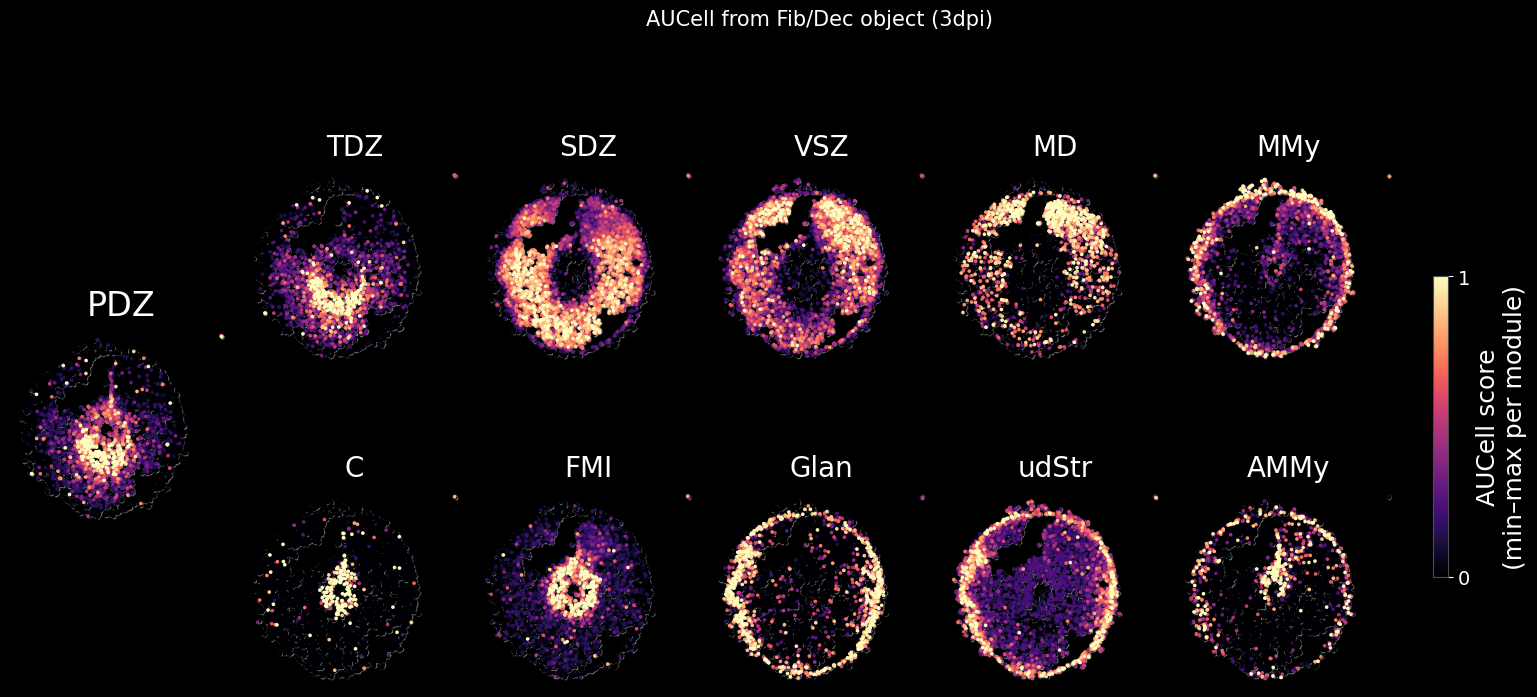

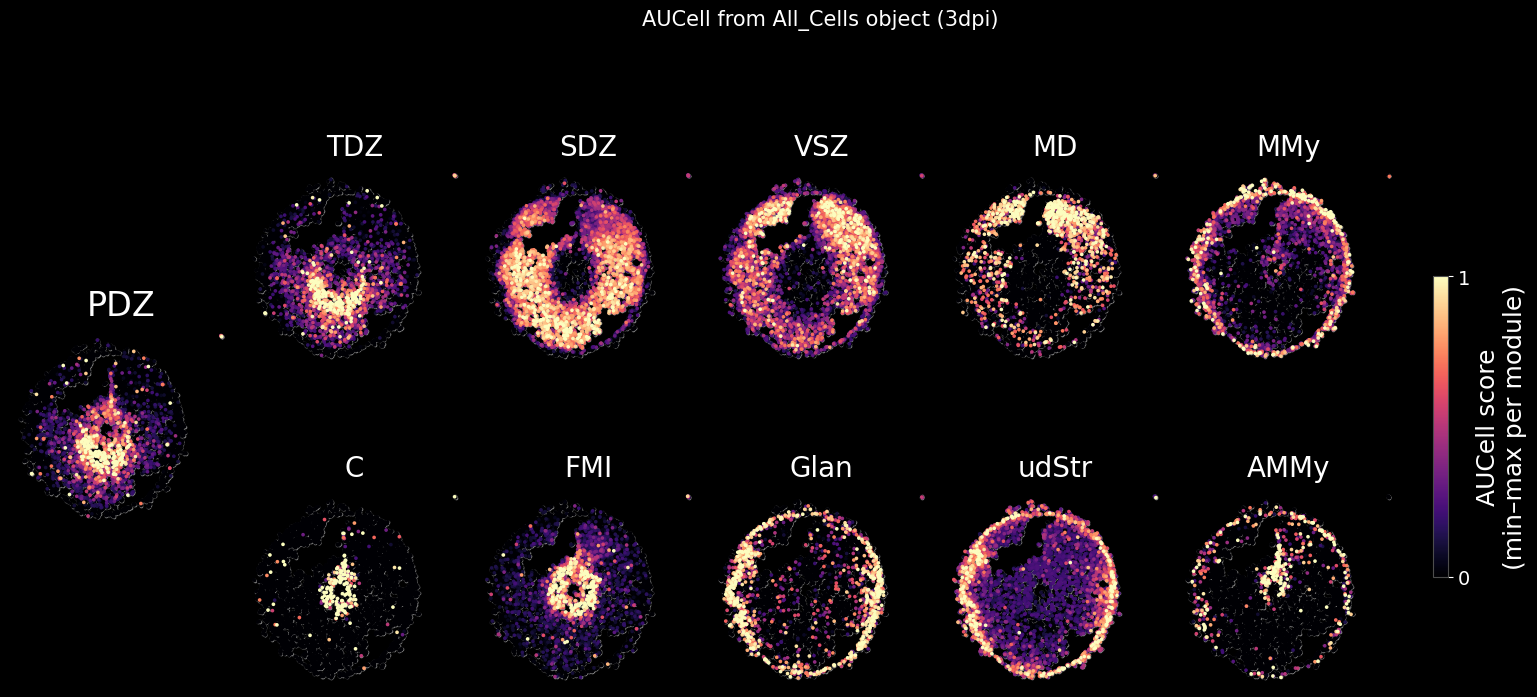

In [29]:
import anndata as ad, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from sklearn.neighbors import NearestNeighbors

SCRATCH = "/n/netscratch/eddy_lab/Everyone/nhilgert"
PANEL_ORDER = ["PDZ","TDZ","SDZ","VSZ","MD","MMy","C","FMI","Glan","udStr","AMMy"]
FEATURE = PANEL_ORDER[0]
CMAP="magma"; BASE_COLOR="0.5"; THETA_DEG=0; FLIP_X=False; FLIP_Y=False
TIMEPOINT_COL="timepoint"; TIMEPOINT_VALUE="3_dpi"
COORD = ["x_um_dbscan","y_um_dbscan"]

def get_xy(a):
    if "spatial" in a.obsm: return np.asarray(a.obsm["spatial"], float)
    for xc,yc in [("x_um_dbscan","y_um_dbscan"),("x_um","y_um")]:
        if {xc,yc}.issubset(a.obs.columns): return a.obs[[xc,yc]].to_numpy(float)
    raise ValueError("no coords")

allc = ad.read_h5ad(f"{SCRATCH}/2026_08_05_Cevrim_XMens_All_Cells.h5ad")
fibd = ad.read_h5ad(f"{SCRATCH}/2026_08_05_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad")

# --- reference cells: 3dpi from Fib/Dec, WITH coords, outlier-filtered ---
fib3 = fibd[fibd.obs[TIMEPOINT_COL].astype(str)==TIMEPOINT_VALUE].copy()
XY_raw = get_xy(fib3)
finite = np.isfinite(XY_raw).all(1)                      # drop NaN-coord cells (the unmatched ones)
print(f"3dpi fib/dec: {fib3.n_obs} cells, {finite.sum()} with coords")
# kNN one-sided 3-MAD outlier removal on the coord-bearing cells
nn = NearestNeighbors(n_neighbors=6).fit(XY_raw[finite]); d,_=nn.kneighbors(XY_raw[finite])
mnd=d[:,1:].mean(1); med=np.median(mnd); mad=np.median(np.abs(mnd-med))
keep_f = mnd <= med + 3*1.4826*mad
keep = np.zeros(fib3.n_obs, bool); keep[np.where(finite)[0][keep_f]] = True
fib3 = fib3[keep].copy()
print(f"after outlier removal: {fib3.n_obs} cells")

# --- restrict to cells also in All_Cells, aligned & ordered identically ---
shared = [b for b in fib3.obs_names if b in set(allc.obs_names)]
fib3 = fib3[shared].copy()
allc_sub = allc[shared].copy()
print(f"shared 3dpi cells (plotted): {len(shared)}")

# --- shared coords + rotation (same cells -> one XY for both plots) ---
XY0 = get_xy(fib3)
XYf = XY0.copy(); cx,cy=np.nanmean(XYf[:,0]),np.nanmean(XYf[:,1])
if FLIP_X: XYf[:,0]=2*cx-XYf[:,0]
if FLIP_Y: XYf[:,1]=2*cy-XYf[:,1]
th=np.deg2rad(THETA_DEG); R=np.array([[np.cos(th),-np.sin(th)],[np.sin(th),np.cos(th)]])
XY=(XYf-[cx,cy])@R.T+[cx,cy]

def plot_from(obs_df, title, outfile):
    def draw(ax, mod, ts=20):
        ax.set_facecolor("black")
        ax.scatter(XY[:,0],XY[:,1],s=7,c=BASE_COLOR,linewidths=0,zorder=1)
        v = obs_df[f"auc_{mod}"].values.astype(float)
        lo,hi=np.percentile(v[np.isfinite(v)],(2,98)); vn=np.clip((v-lo)/(hi-lo+1e-12),0,1); o=np.argsort(vn)
        s=ax.scatter(XY[o,0],XY[o,1],c=vn[o],s=7,cmap=CMAP,vmin=0,vmax=1,linewidths=0,zorder=2)
        ax.set_title(mod,fontsize=ts,color="white",pad=8); ax.set_aspect("equal")
        ax.set_xticks([]);ax.set_yticks([])
        for sp_ in ax.spines.values(): sp_.set_visible(False)
        return s
    others=[m for m in PANEL_ORDER if m!=FEATURE]
    fig=plt.figure(figsize=(3.6*6,3.9*2),facecolor="black")
    gs=GridSpec(2,6,figure=fig,wspace=0.05,hspace=0.15)
    sctr=draw(fig.add_subplot(gs[:,0]),FEATURE,24)
    for i,mod in enumerate(others):
        r,c=divmod(i,5); sctr=draw(fig.add_subplot(gs[r,c+1]),mod)
    cb=fig.colorbar(sctr,ax=fig.axes,shrink=0.5,ticks=[0,1],pad=0.02)
    cb.set_label("AUCell score\n(min–max per module)",color="white",fontsize=18)
    cb.ax.set_yticklabels(["0","1"]);cb.ax.tick_params(colors="white",labelsize=14);cb.outline.set_edgecolor("0.3")
    fig.suptitle(title, color="white", fontsize=15, y=1.03)
    plt.savefig(outfile,dpi=300,bbox_inches="tight",facecolor="black"); plt.show()

plot_from(fib3.obs,     "AUCell from Fib/Dec object (3dpi)",  "aucell_3dpi_from_fibdec.png")
plot_from(allc_sub.obs, "AUCell from All_Cells object (3dpi)", "aucell_3dpi_from_allcells.png")

In [30]:
import anndata as ad, numpy as np, pandas as pd, shutil

SCRATCH = "/n/netscratch/eddy_lab/Everyone/nhilgert"
allc = ad.read_h5ad(f"{SCRATCH}/2026_08_05_Cevrim_XMens_All_Cells.h5ad", backed="r")
fibd = ad.read_h5ad(f"{SCRATCH}/2026_08_05_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad")

auc_cols = [c for c in allc.obs.columns if c.startswith("auc_")]
print(f"transferring {len(auc_cols)} auc columns from All_Cells")

# align All_Cells auc values to the fib/dec cells by obs_names
allc_auc = allc.obs[auc_cols].reindex(fibd.obs_names)
matched = int(allc_auc[auc_cols[0]].notna().sum())
print(f"matched {matched}/{fibd.n_obs} fib/dec cells to All_Cells scores")
if matched < fibd.n_obs:
    print(f"  {fibd.n_obs - matched} cells not in All_Cells -> NaN (unexpected — fib/dec should be subset)")

# OPTION A (non-destructive): add as auc_wholeobj_* , keep native auc_*
for c in auc_cols:
    fibd.obs[f"auc_wholeobj_{c[4:]}"] = allc_auc[c].values

# OPTION B (overwrite native auc_* with whole-object values) — uncomment if that's what you want:
# for c in auc_cols:
#     fibd.obs[c] = allc_auc[c].values

# write safely (temp + move, to avoid the truncation error)
allc.file.close()
tmp = f"{SCRATCH}/_tmp_fibdec.h5ad"
fibd.write_h5ad(tmp); del fibd
shutil.move(tmp, f"{SCRATCH}/2026_08_05_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad")
print("wrote fib/dec object with whole-object scores added")

transferring 11 auc columns from All_Cells
matched 43197/43197 fib/dec cells to All_Cells scores
wrote fib/dec object with whole-object scores added


In [31]:
import anndata as ad, numpy as np, pandas as pd, shutil

SCRATCH = "/n/netscratch/eddy_lab/Everyone/nhilgert"
allc = ad.read_h5ad(f"{SCRATCH}/2026_08_05_Cevrim_XMens_All_Cells.h5ad", backed="r")
fibd = ad.read_h5ad(f"{SCRATCH}/2026_08_05_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad")

auc_cols = [c for c in allc.obs.columns if c.startswith("auc_")]
print(f"transferring {len(auc_cols)} auc columns: {auc_cols}")

# align All_Cells auc scores to fib/dec cells by obs_names (fib/dec is a subset of All_Cells)
allc_auc = allc.obs[auc_cols].reindex(fibd.obs_names)
matched = int(allc_auc[auc_cols[0]].notna().sum())
print(f"matched {matched}/{fibd.n_obs} cells")
if matched < fibd.n_obs:
    print(f"  ⚠ {fibd.n_obs - matched} cells NOT matched by obs_names — STOP and check before writing")

# OVERWRITE native auc_* with whole-object values
for c in auc_cols:
    fibd.obs[c] = allc_auc[c].values

# safe write (temp + move)
allc.file.close()
tmp = f"{SCRATCH}/_tmp_fibdec.h5ad"
fibd.write_h5ad(tmp); del fibd
shutil.move(tmp, f"{SCRATCH}/2026_08_05_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad")
print("done — fib/dec auc_* now hold whole-object AUCell scores")

transferring 11 auc columns: ['auc_MMy', 'auc_MD', 'auc_VSZ', 'auc_FMI', 'auc_C', 'auc_PDZ', 'auc_TDZ', 'auc_SDZ', 'auc_udStr', 'auc_Glan', 'auc_AMMy']
matched 43197/43197 cells
done — fib/dec auc_* now hold whole-object AUCell scores


In [32]:
import anndata as ad
SCRATCH = "/n/netscratch/eddy_lab/Everyone/nhilgert"
for f in ["2026_08_05_Cevrim_Human_All_Cells.h5ad", "2026_08_05_Cevrim_Human_Only_Fib_Dec_Cells.h5ad",
          "2026_08_05_Cevrim_XMens_All_Cells.h5ad", "2026_08_05_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad"]:
    try:
        a = ad.read_h5ad(f"{SCRATCH}/{f}", backed="r")
        leiden = [c for c in a.obs.columns if "leiden" in c.lower()]
        auc = [c for c in a.obs.columns if c.startswith("auc_")]
        has_coords = "x_um_dbscan" in a.obs.columns
        print(f"{f}: {a.n_obs} cells | cell_type={'cell_type' in a.obs.columns} "
              f"cell_subtype={'cell_subtype' in a.obs.columns} | auc={len(auc)} | "
              f"leiden_left={len(leiden)} | coords={has_coords} | layers={list(a.layers)}")
    except Exception as e:
        print(f"{f}: ⚠ ERROR {e}")

2026_08_05_Cevrim_Human_All_Cells.h5ad: 66830 cells | cell_type=True cell_subtype=True | auc=0 | leiden_left=0 | coords=True | layers=['counts']
2026_08_05_Cevrim_Human_Only_Fib_Dec_Cells.h5ad: 47533 cells | cell_type=True cell_subtype=True | auc=0 | leiden_left=0 | coords=True | layers=['counts']
2026_08_05_Cevrim_XMens_All_Cells.h5ad: 57033 cells | cell_type=True cell_subtype=True | auc=11 | leiden_left=0 | coords=True | layers=['counts']
2026_08_05_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad: 43197 cells | cell_type=True cell_subtype=True | auc=22 | leiden_left=0 | coords=True | layers=['counts']


In [33]:
import anndata as ad
SCRATCH = "/n/netscratch/eddy_lab/Everyone/nhilgert"
a = ad.read_h5ad(f"{SCRATCH}/2026_08_05_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad", backed="r")
auc = sorted([c for c in a.obs.columns if c.startswith("auc_")])
print(f"{len(auc)} auc columns:")
for c in auc: print(f"  {c}")

22 auc columns:
  auc_AMMy
  auc_C
  auc_FMI
  auc_Glan
  auc_MD
  auc_MMy
  auc_PDZ
  auc_SDZ
  auc_TDZ
  auc_VSZ
  auc_udStr
  auc_wholeobj_AMMy
  auc_wholeobj_C
  auc_wholeobj_FMI
  auc_wholeobj_Glan
  auc_wholeobj_MD
  auc_wholeobj_MMy
  auc_wholeobj_PDZ
  auc_wholeobj_SDZ
  auc_wholeobj_TDZ
  auc_wholeobj_VSZ
  auc_wholeobj_udStr


In [34]:
import anndata as ad, shutil
SCRATCH = "/n/netscratch/eddy_lab/Everyone/nhilgert"
a = ad.read_h5ad(f"{SCRATCH}/2026_08_05_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad")

modules = ["MMy","MD","VSZ","FMI","C","PDZ","TDZ","SDZ","udStr","Glan","AMMy"]

# copy wholeobj values into the plain auc_ names, then drop the wholeobj columns
for m in modules:
    assert f"auc_wholeobj_{m}" in a.obs.columns, f"missing auc_wholeobj_{m}"
    a.obs[f"auc_{m}"] = a.obs[f"auc_wholeobj_{m}"].values      # plain auc_ now = wholeobj values

drop = [c for c in a.obs.columns if c.startswith("auc_wholeobj_")]
a.obs.drop(columns=drop, inplace=True)

remaining = sorted([c for c in a.obs.columns if c.startswith("auc_")])
print(f"after: {len(remaining)} auc columns -> {remaining}")
assert len(remaining) == 11, f"expected 11, got {len(remaining)}"

# safe write (temp + move)
tmp = f"{SCRATCH}/_tmp_fibdec.h5ad"
a.write_h5ad(tmp); del a
shutil.move(tmp, f"{SCRATCH}/2026_08_05_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad")
print("done — 11 auc_ columns holding whole-object scores")

after: 11 auc columns -> ['auc_AMMy', 'auc_C', 'auc_FMI', 'auc_Glan', 'auc_MD', 'auc_MMy', 'auc_PDZ', 'auc_SDZ', 'auc_TDZ', 'auc_VSZ', 'auc_udStr']
done — 11 auc_ columns holding whole-object scores


In [36]:

import anndata as ad, numpy as np
SCRATCH = "/n/netscratch/eddy_lab/Everyone/nhilgert"
allc = ad.read_h5ad(f"{SCRATCH}/2026_08_05_Cevrim_XMens_All_Cells.h5ad", backed="r")
fibd = ad.read_h5ad(f"{SCRATCH}/2026_08_05_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad", backed="r")
print("auc count:", len([c for c in fibd.obs.columns if c.startswith("auc_")]))   # should be 11
shared = [b for b in fibd.obs_names[:200] if b in set(allc.obs_names)]
diff = np.abs(fibd.obs.loc[shared,"auc_PDZ"].values - allc.obs.loc[shared,"auc_PDZ"].values).max()
print(f"max diff auc_PDZ (fib vs allc): {diff:.2e}")   # ~0 confirms plain auc_ now holds whole-object values

auc count: 11
max diff auc_PDZ (fib vs allc): 0.00e+00


In [37]:
import anndata as ad
DEST = "/n/lab_storage/eddy_lab/Lab/mckinley_backup_2025-12-18/data"
for f in ["2026_08_21_Cevrim_Human_All_Cells.h5ad", "2026_08_21_Cevrim_Human_Only_Fib_Dec_Cells.h5ad",
          "2026_08_21_Cevrim_XMens_All_Cells.h5ad", "2026_08_21_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad"]:
    try:
        a = ad.read_h5ad(f"{DEST}/{f}", backed="r")
        auc = len([c for c in a.obs.columns if c.startswith("auc_")])
        print(f"✓ {f}: {a.n_obs} cells, auc={auc}, coords={'x_um_dbscan' in a.obs.columns}")
    except Exception as e:
        print(f"⚠ {f}: {e}")

✓ 2026_08_21_Cevrim_Human_All_Cells.h5ad: 66830 cells, auc=0, coords=True
✓ 2026_08_21_Cevrim_Human_Only_Fib_Dec_Cells.h5ad: 47533 cells, auc=0, coords=True
✓ 2026_08_21_Cevrim_XMens_All_Cells.h5ad: 57033 cells, auc=11, coords=True
✓ 2026_08_21_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad: 43197 cells, auc=11, coords=True


In [ ]:
import anndata as ad, scanpy as sc, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from ctxcore.genesig import GeneSignature
from pyscenic.aucell import aucell, derive_auc_threshold

SCRATCH = "/n/netscratch/eddy_lab/Everyone/nhilgert"
COUNTS_LAYER = "counts"
MODULE_NAME = "stromal"                       # column -> auc_stromal
MODULE_GENES = ["AEBP1","APOD","ASPN","BGN","C7","CCDC80","COL14A1","COL6A2","CTSK","CXCL12",
                "DCN","DPT","GPNMB","IGFBP5","IGFBP6","LUM","MGP","OGN","PLAC9","SCN7A",
                "SERPINF1","SFRP1","SPOCK1","SPON2","TIMP2"]
TP_COL = "timepoint"
XCOL, YCOL = "x_um_dbscan", "y_um_dbscan"
CMAP = "magma"; BASE_COLOR = "0.5"

a = ad.read_h5ad(f"{SCRATCH}/2026_08_21_Cevrim_Human_All_Cells.h5ad")
print(f"{a.n_obs} cells")

# --- gene hit rate ---
present = [g for g in MODULE_GENES if g in a.var_names]
missing = [g for g in MODULE_GENES if g not in a.var_names]
print(f"genes present: {len(present)}/{len(MODULE_GENES)}")
if missing: print(f"  missing: {missing}")
assert present, "no genes found"

# --- AUCell (CP10k from counts, no log) ---
m = a.copy(); m.X = m.layers[COUNTS_LAYER].copy()
sc.pp.normalize_total(m, target_sum=1e4)
ex = pd.DataFrame(m.X.toarray() if hasattr(m.X,"toarray") else np.asarray(m.X),
                  index=m.obs_names, columns=m.var_names)
thr = derive_auc_threshold(ex)[0.01]
auc = aucell(ex, [GeneSignature(name=MODULE_NAME, gene2weight=present)],
             auc_threshold=thr, num_workers=8).reindex(a.obs_names)
a.obs[f"auc_{MODULE_NAME}"] = auc[MODULE_NAME].values
print(f"auc_threshold={thr:.4f}; scored auc_{MODULE_NAME}")

# --- coords + timepoints (coords unique per timepoint -> facet) ---
XYall = a.obs[[XCOL, YCOL]].to_numpy(float)
has_coord = np.isfinite(XYall).all(1)
print(f"cells with coords: {has_coord.sum()}/{a.n_obs}")
timepoints = sorted(a.obs[TP_COL].astype(str).unique())
tps_with_coords = [t for t in timepoints
                   if (has_coord & (a.obs[TP_COL].astype(str)==t).values).sum() > 0]
print(f"timepoints with coords: {tps_with_coords}")

# --- facet: one panel per timepoint (separate coordinate frames), shared color scale ---
v_all = a.obs[f"auc_{MODULE_NAME}"].values.astype(float)
lo, hi = np.percentile(v_all[np.isfinite(v_all) & has_coord], (2, 98))

n = len(tps_with_coords)
fig, axes = plt.subplots(1, n, figsize=(5.2*n, 5.2), squeeze=False, facecolor="black")
for j, t in enumerate(tps_with_coords):
    ax = axes[0, j]; ax.set_facecolor("black")
    mt = has_coord & (a.obs[TP_COL].astype(str) == t).values
    xy = XYall[mt]
    v = np.clip((v_all[mt] - lo) / (hi - lo + 1e-12), 0, 1)
    o = np.argsort(v)
    ax.scatter(xy[:,0], xy[:,1], s=7, c=BASE_COLOR, linewidths=0, zorder=1)   # grey base
    s = ax.scatter(xy[o,0], xy[o,1], c=v[o], s=7, cmap=CMAP, vmin=0, vmax=1, linewidths=0, zorder=2)
    ax.set_title(f"{t}  (n={int(mt.sum())})", fontsize=16, color="white", pad=8)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_visible(False)
cb = fig.colorbar(s, ax=axes, shrink=0.6, ticks=[0,1], pad=0.02)
cb.set_label(f"{MODULE_NAME} AUCell\n(min–max)", color="white", fontsize=15)
cb.ax.set_yticklabels(["0","1"]); cb.ax.tick_params(colors="white", labelsize=13); cb.outline.set_edgecolor("0.3")
fig.suptitle(f"{MODULE_NAME} module (human, {len(present)}/{len(MODULE_GENES)} genes)",
             color="white", fontsize=16, y=1.02)
plt.savefig(f"human_spatial_{MODULE_NAME}.png", dpi=300, bbox_inches="tight", facecolor="black")
plt.show()

66830 cells
genes present: 25/25
